# EDA – metadata her ze Steamu

## Popis dat

#### Načtení dat

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("src")  # kód projektu je ve složce src/
from prepare_data import REPO, REVISION, download_metadata, load_metadata

path = download_metadata()
df = load_metadata(path)
download_date = pd.Timestamp(path.stat().st_mtime, unit="s").normalize()

print("Dataset:", REPO)
print("Revize:", REVISION)
print("Staženo:", download_date.date())

e:\Uni\XDEEP - Projekt\Projekt\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: FronkonGames/steam-games-dataset
Revize: 6c21457b9ebf0a6a7f5b91e11281d65d456ea30e
Staženo: 2026-11-15


#### Počet řádků a sloupců

In [2]:
df.shape

(148909, 42)

#### Náhled dat

In [3]:
df.head()

,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,header_image,...,positive,negative,estimated_owners,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags
app_id,,,,,,,,,,,,,,,,,,,,,
2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0,0.00,0,,,,,https://shared.akamai.steamstatic.com/store_it...,...,0,0,0 - 0,0,0,0,0,0,0,[]
496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0,5.24,0,"Springtime, April: when the cherry trees come ...","Springtime, April: when the cherry trees come ...","Spring has come, and our protagonist, Yukinari...",,https://shared.akamai.steamstatic.com/store_it...,...,252,3,0 - 20000,8,0,8,0,65,0,"{'Adventure': 27, 'Visual Novel': 19, 'Anime':..."
1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0,4.99,0,"Immerse yourself in the most beloved, mystical...","Immerse yourself in the most beloved, mystical...",Discover an entrancing and spectacular world!,,https://shared.akamai.steamstatic.com/store_it...,...,21,3,0 - 20000,0,0,0,0,0,0,"{'Casual': 83, 'Card Game': 52, 'Solitaire': 4..."
3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0,8.99,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...","synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",Yuha! I'll start the broadcast! Hakko's extrem...,,https://shared.akamai.steamstatic.com/store_it...,...,0,0,0 - 20000,0,0,0,0,0,1,[]
3631080,Maze Quest VR,"Apr 24, 2025",0,4.99,0,Its not just a Maze; its a Quest! Enter the ca...,Its not just a Maze; its a Quest! Enter the ca...,Its not just a Maze; its a Quest! Enter the ca...,,https://shared.akamai.steamstatic.com/store_it...,...,0,0,0 - 20000,0,0,0,0,0,0,[]


#### Sloupce a datové typy

In [4]:
df.info()

<class 'pandas.DataFrame'>
Index: 148909 entries, 2539430 to 2953170
Data columns (total 42 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   name                      148909 non-null  str    
 1   release_date              148909 non-null  str    
 2   required_age              148909 non-null  int64  
 3   price                     148909 non-null  float64
 4   dlc_count                 148909 non-null  int64  
 5   detailed_description      148909 non-null  str    
 6   about_the_game            148909 non-null  str    
 7   short_description         148909 non-null  str    
 8   reviews                   148909 non-null  str    
 9   header_image              148909 non-null  str    
 10  website                   148909 non-null  str    
 11  support_url               148909 non-null  str    
 12  support_email             148909 non-null  str    
 13  windows                   148909 non-null  bool   
 1

#### Pomocné sloupce
Počet recenzí a datum vydání se používají ve více buňkách, proto se počítají jednou.

In [5]:
n_reviews = df["positive"] + df["negative"]
release = pd.to_datetime(df["release_date"], format="mixed", errors="coerce")

## 1. Přehled recenzí

#### Celkový počet recenzí

In [6]:
pos = df["positive"].sum()
neg = df["negative"].sum()
total = pos + neg
print("Celkem recenzí:", total)
print(f"Pozitivní: {pos} ({pos / total:.1%})")
print(f"Negativní: {neg} ({neg / total:.1%})")

Celkem recenzí: 148914706
Pozitivní: 128157955 (86.1%)
Negativní: 20756751 (13.9%)


#### Hry s nulovým počtem recenzí
Hry s `recommendations > 0` recenze určitě mají, nula u nich tedy neznamená „žádné recenze“, ale chybějící data.

In [7]:
zero = n_reviews == 0
print("Hry s 0 recenzemi:", zero.sum())
print("  z toho recommendations > 0 (chybějící label):", (zero & (df["recommendations"] > 0)).sum())

Hry s 0 recenzemi: 65916
  z toho recommendations > 0 (chybějící label): 3467


## 2. Extrémní hodnoty

#### Numerické sloupce

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
required_age,148909.0,0.145868,1.543098,0.0,0.00,0.00,0.00,21.00
price,148909.0,5.045483,12.262702,0.0,0.74,2.99,5.99,999.99
dlc_count,148909.0,0.494960,13.232717,0.0,0.00,0.00,0.00,3703.00
metacritic_score,148909.0,2.127373,12.481296,0.0,0.00,0.00,0.00,97.00
achievements,148909.0,17.466607,128.702564,0.0,0.00,3.00,19.00,9821.00
recommendations,148909.0,798.712005,19858.223888,0.0,0.00,0.00,0.00,4830455.00
user_score,148909.0,0.020214,1.265782,0.0,0.00,0.00,0.00,100.00
positive,148909.0,860.646133,25493.862305,0.0,0.00,1.00,23.00,7642084.00
negative,148909.0,139.392186,4877.447662,0.0,0.00,0.00,6.00,1173003.00
average_playtime_forever,148909.0,171.554553,10179.359844,0.0,0.00,0.00,0.00,3429544.00


#### Nejdražší hry

In [9]:
cols = ["name", "price", "positive", "negative"]
display(df.nlargest(10, "price")[cols])

,name,price,positive,negative
app_id,,,,
4693030,Congratulations On Your Purchase,999.99,0,0
2504210,The Leverage Game Business Edition,999.98,0,0
2499620,The Leverage Game,999.98,1,0
1200520,Ascent Free-Roaming VR Experience,999.00,6,1
3013840,True Love,500.00,3,1
1105450,Aartform Curvy 3D 4.0,299.99,10,2
253670,Aartform Curvy 3D 3.0,299.90,32,13
502570,Houdini Indie,269.99,233,18
2023640,Hidden Industries Top-Down 3D,199.99,10,2


#### Zdarma hry

In [10]:
free = df["price"] == 0
print(f"Hry s cenou 0: {free.sum()} ({free.mean():.1%})")

Hry s cenou 0: 29275 (19.7%)


#### Hry s nejvíce recenzemi

In [11]:
top = df.loc[n_reviews.nlargest(10).index, cols].copy()
for c in ["positive", "negative"]:
    top[c] = [f"{v} ({v / n:.1%})" for v, n in zip(top[c], n_reviews[top.index])]
display(top)

,name,price,positive,negative
app_id,,,,
730,Counter-Strike 2,0.00,7642084 (86.7%),1173003 (13.3%)
578080,PUBG: BATTLEGROUNDS,0.00,1520457 (59.4%),1037487 (40.6%)
570,Dota 2,0.00,2037143 (81.5%),461826 (18.5%)
271590,Grand Theft Auto V Legacy,0.00,1739980 (87.4%),250576 (12.6%)
105600,Terraria,4.99,1373979 (97.5%),35494 (2.5%)
359550,Tom Clancy's Rainbow Six® Siege X,0.00,1172854 (83.9%),225730 (16.1%)
252490,Rust,19.99,1071135 (87.2%),156649 (12.8%)
440,Team Fortress 2,0.00,1044264 (89.9%),117208 (10.1%)
4000,Garry's Mod,4.99,1122546 (96.8%),37161 (3.2%)


#### Věková hranice

In [12]:
print("Hodnoty required_age:", sorted(df["required_age"].unique().tolist()))

Hodnoty required_age: [0, 1, 3, 6, 7, 8, 10, 12, 13, 14, 15, 16, 17, 18, 20, 21]


## 3. Žánry, kategorie, jazyky a screenshoty

In [13]:
counts = pd.DataFrame({
    "genres": df["genres"].map(len),
    "categories": df["categories"].map(len),
    "supported_languages": df["supported_languages"].map(len),
    "screenshots": df["screenshots"].map(len),
})
display(counts.describe().T)
print("Hry s 0 položkami:")
print((counts == 0).sum())

,count,mean,std,min,25%,50%,75%,max
genres,148909.0,2.719661,1.458011,0.0,2.0,3.0,4.0,19.0
categories,148909.0,4.623092,3.456697,0.0,2.0,4.0,6.0,32.0
supported_languages,148909.0,5.527685,13.659698,0.0,1.0,1.0,5.0,103.0
screenshots,148909.0,8.328530,5.480058,0.0,5.0,7.0,10.0,183.0


Hry s 0 položkami:
genres                 8437
categories             8981
supported_languages    8402
screenshots            6039
dtype: int64


#### Žánry

In [14]:
df["genres"].explode().value_counts()

genres
Indie                    99608
Casual                   63109
Action                   54828
Adventure                53367
Simulation               31243
Strategy                 28688
RPG                      25479
Free To Play             15181
Early Access             14951
Sports                    5768
Racing                    4726
Massively Multiplayer     3026
Utilities                 1124
Design & Illustration      596
Animation & Modeling       494
Education                  468
Violent                    414
Video Production           346
Game Development           329
Gore                       257
Audio Production           233
Software Training          225
Photo Editing              187
Web Publishing             114
Nudity                      94
Sexual Content              88
Accounting                  32
Movie                        2
Documentary                  1
Episodic                     1
Short                        1
Tutorial                     1
3

#### Software
Záznamy, jejichž žánry jsou výhradně softwarové (nejde o hry).

In [15]:
from prepare_data import is_software

print("Záznamy jen se softwarovými žánry:", df["genres"].map(is_software).sum())

Záznamy jen se softwarovými žánry: 938


#### Kategorie

In [16]:
df["categories"].explode().value_counts()

categories
Single-player                        133031
Family Sharing                       120774
Steam Achievements                    70208
Steam Cloud                           40023
Full controller support               31281
                                      ...  
#category_playable_without_vision        51
Chat Speech-to-text                      43
SteamVR Collectibles                     38
Mods (require HL2)                        2
Mods                                      2
Name: count, Length: 65, dtype: int64

#### Jazyky
Nejvzácnější hodnoty ukážou případné chybné názvy jazyků.

In [17]:
langs = df["supported_languages"].explode().value_counts()
print("Počet unikátních hodnot:", len(langs))
display(langs.tail(20))

Počet unikátních hodnot: 132


supported_languages
#lang_slovakian                                                         2
German;                                                                 2
German[b][/b]                                                           2
Italian \r\n\r\n[b][/b]                                                 1
Japanese (all with full audio support)                                  1
English\r\nRussian\r\nSpanish - Spain\r\nJapanese\r\nCzech              1
 Korean                                                                 1
\r\nFrench                                                              1
\r\nGerman                                                              1
Russian\r\nEnglish\r\nSpanish - Spain\r\nFrench\r\nJapanese\r\nCzech    1
Traditional Chinese (text only)                                         1
Hungarian,Polish                                                        1
Russian\r\n[b][/b]                                                      1
English Dutch  Eng

#### Screenshoty a header

In [18]:
print("Hry s méně než 3 screenshoty:", (counts["screenshots"] < 3).sum())
print("Hry bez header_image:", (df["header_image"] == "").sum())

Hry s méně než 3 screenshoty: 7628
Hry bez header_image: 86


## 4. Datum vydání

#### Kontrola data vydání

In [19]:
print("Nepřevoditelná data:", release.isna().sum())
print("Rozsah data vydání:", release.min(), "-", release.max())
print("Vydáno po datu stažení:", (release > download_date).sum())

Nepřevoditelná data: 0
Rozsah data vydání: 1997-06-30 00:00:00 - 2026-12-01 00:00:00
Vydáno po datu stažení: 1


## 5. Duplicity
Jednotkou rozdělení dat je hra – stejná hra se nesmí objevit zároveň v trénovací a testovací množině.

#### Duplicitní app_id

In [20]:
print("Duplicitní app_id:", df.index.duplicated().sum())

Duplicitní app_id: 0


#### Stejná hra pod více app_id
Hry se stejným názvem a stejnými vývojáři pod různými `app_id`.

In [21]:
key = df["name"].str.lower() + " | " + df["developers"].map(", ".join)
dup = df[key.duplicated(keep=False)].assign(key=key, n_reviews=n_reviews)
print(f"{dup.shape[0]} her sdílí název a vývojáře s jinou hrou:")
display(dup.sort_values("key")[["name", "release_date", "price", "n_reviews"]].head(20))

253 her sdílí název a vývojáře s jinou hrou:


,name,release_date,price,n_reviews
app_id,,,,
34019,Alpha Protocol™,"Jun 1, 2010",9.99,4045
34010,Alpha Protocol™,"Jun 1, 2010",9.99,4911
2383950,Anvil Playtest,"Apr 7, 2023",0.00,0
1648440,ANVIL Playtest,"Jun 9, 2021",0.00,0
2447870,Artifice Playtest,"Jun 12, 2023",0.00,0
2206090,Artifice Playtest,"Nov 17, 2022",0.00,0
2268670,Ascendant Playtest,"Jan 13, 2023",0.00,0
2338060,Ascendant Playtest,"Nov 14, 2024",0.00,0
48173,Assassin's Creed 2,"Mar 9, 2010",4.99,18460


## 6. Nulové recenze podle roku vydání

#### Podíl her s 0 recenzemi po letech
Sloupce tabulky pro každý rok vydání:
- `games` – počet her,
- `zero_share` – podíl her s 0 recenzemi,
- `missing_share` – podíl her s 0 recenzemi mezi hrami s `recommendations > 0`, tedy podíl chybějících labelů.

In [22]:
year = release.dt.year
has_rec = df["recommendations"] > 0
table = pd.DataFrame({
    "games": zero.groupby(year).size(),
    "zero_share": zero.groupby(year).mean(),
    "missing_share": zero[has_rec].groupby(year[has_rec]).mean(),
}).round(3)
table.loc[2010:]

,games,zero_share,missing_share
release_date,,,
2010,255,0.024,0.016
2011,260,0.000,0.000
2012,322,0.000,0.000
2013,468,0.049,0.050
2014,1524,0.007,0.007
2015,2518,0.007,0.006
2016,4143,0.006,0.001
2017,5927,0.017,0.001
2018,7461,0.037,0.013


#### Poměr recenzí a recommendations po letech
Medián poměru počtu recenzí a `recommendations` u her, které mají obojí. Pokud u novějších let klesá, jsou počty recenzí podhodnocené.

release_date
2010    1.292327
2011    1.430769
2012    1.427679
2013    1.426334
2014    1.312638
2015    1.258172
2016    1.222421
2017    1.140727
2018    1.125000
2019    1.120000
2020    1.098271
2021    1.085107
2022    1.061644
2023    1.059151
2024    0.989707
2025    0.814953
dtype: float64

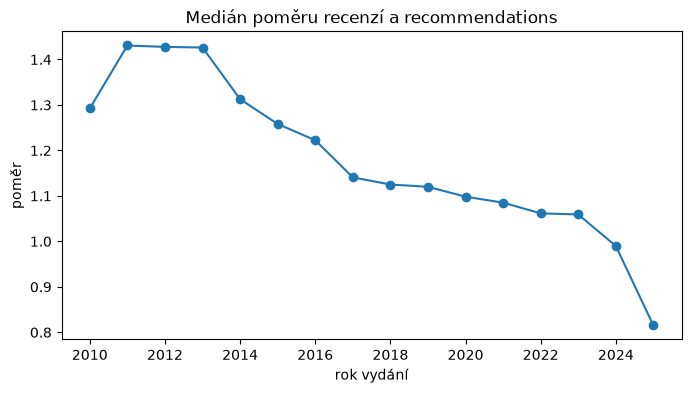

In [23]:
ok = (n_reviews > 0) & (df["recommendations"] > 0)
ratio = (n_reviews[ok] / df.loc[ok, "recommendations"]).groupby(year[ok]).median()
display(ratio.loc[2010:])

ratio.loc[2010:].plot(marker="o", figsize=(8, 4), title="Medián poměru recenzí a recommendations")
plt.xlabel("rok vydání")
plt.ylabel("poměr")
plt.show()

Poměr v letech 2011–2023 pozvolna klesá z přibližně 1,43 na 1,06, bez skoku. Od roku 2024 klesá výrazně (0,99, v roce 2025 0,81) – počty recenzí novějších her jsou podhodnocené. Nenulové počty recenzí jsou tedy spolehlivé do roku 2023, proto se data omezují na hry vydané do roku 2023.

## 7. Předzpracování dat
### Čištění
Implementováno ve funkci `clean()` v `prepare_data.py`.

1. **Datum vydání do roku 2023** – poměr recenzí a `recommendations` je do roku 2023 stabilní, od roku 2024 klesá (sekce 6).
2. **Hry s aspoň 1 recenzí** – nulu nelze odlišit od chybějících dat (sekce 1 a 6).
3. **Aspoň 3 screenshoty a `header_image`** – obrázky jsou vstupem modelu (sekce 3).
4. **Bez softwaru** – záznamy pouze se softwarovými žánry nejsou hry (sekce 3).
5. **Bez playtestů a duplicit** – u stejné hry pod více `app_id` zůstává záznam s nejvíce recenzemi (sekce 5).
6. **Oprava jazyků** – z chybně zapsaných položek (HTML/BBCode zbytky, více jazyků v jedné položce, poznámky v závorkách) se názvy jazyků vytáhnou regulárním výrazem (sekce 3).
7. **Vstupy pouze známé před vydáním** – recenze, `recommendations`, vlastníci, CCU, herní doba, `tags` a DLC vznikají až po vydání (leakage).

#### Počet her po jednotlivých krocích

In [24]:
from prepare_data import clean

df_clean = clean(df)

Původně: 148909
Vydáno do 2023: 77575
Aspoň 1 recenze: 64675
Aspoň 3 screenshoty a header: 64554
Bez softwaru: 63889
Bez playtestů: 63889
Bez duplicit: 63804


#### Hry bez žánrů, kategorií nebo jazyků po čištění

In [25]:
(df_clean[["genres", "categories", "supported_languages"]].map(len) == 0).sum()

genres                  96
categories             202
supported_languages     19
dtype: int64

#### Jazyky po opravě

In [26]:
langs_clean = df_clean["supported_languages"].explode().value_counts()
print("Počet unikátních hodnot:", len(langs_clean))
display(langs_clean.tail(20))

Počet unikátních hodnot: 104


supported_languages
Punjabi (Shahmukhi)    515
Sindhi                 515
Turkmen                515
Xhosa                  515
Yoruba                 515
Amharic                514
Assamese               514
Konkani                514
Odia                   514
Dari                   513
Sorani                 513
Sotho                  513
Tswana                 513
Valencian              513
Cherokee               512
K'iche'                512
Quechua                512
Tigrinya               512
Wolof                  512
English Dutch            1
Name: count, dtype: int64

#### Hry s téměř všemi jazyky
Počet her, které uvádějí téměř všechny jazyky, jež Steam nabízí (90 a více).

In [27]:
print("Hry s 90+ jazyky:", (df_clean["supported_languages"].map(len) >= 90).sum())

Hry s 90+ jazyky: 510


### Rozdělení dat
Časové rozdělení podle roku vydání (funkce `split()` v `prepare_data.py`): trénovací množina do roku 2021,
validační rok 2022, testovací rok 2023. Model se tak vyhodnocuje na hrách vydaných později než trénovací data
a jedna hra je vždy jen v jedné množině.

#### Počet her po letech

In [28]:
df_clean["release"].dt.year.value_counts().sort_index()

release
1997       2
1998       1
1999       2
2000       2
2001       4
2002       1
2003       3
2004       5
2005       7
2006      62
2007      84
2008     152
2009     293
2010     238
2011     250
2012     313
2013     432
2014    1485
2015    2448
2016    4046
2017    5707
2018    7064
2019    6566
2020    7951
2021    8447
2022    8611
2023    9628
Name: count, dtype: int64

#### Velikost množin

In [29]:
from prepare_data import split

train, val, test = split(df_clean)
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {len(part)} her ({len(part) / len(df_clean):.1%})")

train: 45565 her (71.4%)
val: 8611 her (13.5%)
test: 9628 her (15.1%)


### Analýza trénovacích dat
Pouze na trénovací množině, aby výběr a kódování vstupů neovlivnila validační a testovací data.

#### Rozdělení cílové proměnné

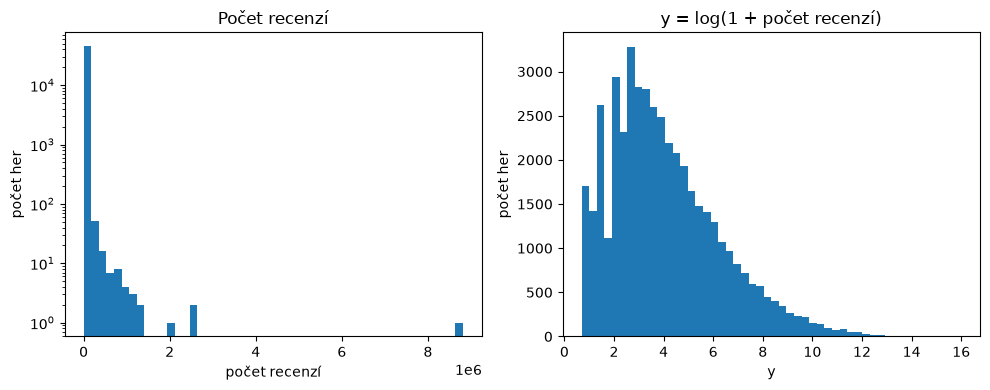

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(train["n_reviews"], bins=50)
ax[0].set(title="Počet recenzí", xlabel="počet recenzí", ylabel="počet her", yscale="log")
ax[1].hist(train["y"], bins=50)
ax[1].set(title="y = log(1 + počet recenzí)", xlabel="y", ylabel="počet her")
plt.tight_layout()
plt.show()

Počet recenzí je extrémně nerovnoměrný – téměř všechny hry spadají do prvního intervalu histogramu, zatímco jednotlivé hry mají miliony recenzí.
Při regresi přímo na počtu recenzí by loss ovládlo několik nejpopulárnějších her a stejný absolutní rozdíl by u malé a velké hry znamenal něco úplně jiného.

Po transformaci `y = log(1 + počet recenzí)` je rozdělení výrazně vyrovnanější a chyba vyjadřuje relativní rozdíl – MAE = 1 odpovídá chybě zhruba e ≈ 2,7krát.
Model proto predikuje `y`.

#### Cílová proměnná podle roku vydání

,count,mean,median
release,,,
2010,238,6.19,5.96
2011,250,6.86,6.67
2012,313,7.16,7.02
2013,432,7.35,7.13
2014,1485,6.02,5.78
2015,2448,5.33,5.06
2016,4046,4.74,4.51
2017,5707,4.06,3.76
2018,7064,3.73,3.40


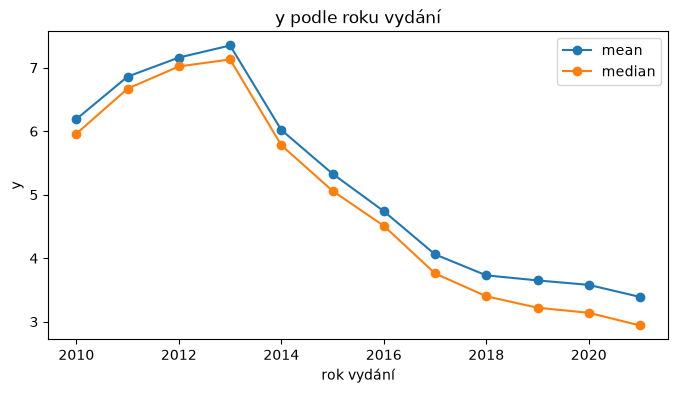

In [31]:
by_year = train.groupby(train["release"].dt.year)["y"].agg(["count", "mean", "median"]).loc[2010:].round(2)
display(by_year)

by_year[["mean", "median"]].plot(marker="o", figsize=(8, 4), title="y podle roku vydání")
plt.xlabel("rok vydání")
plt.ylabel("y")
plt.show()

#### Cena

,count,mean,median
price,,,
zdarma,6300,4.59,4.13
do 5,28547,3.85,3.47
5–10,6888,4.14,3.64
10–20,3242,4.43,4.01
nad 20,588,4.80,4.10


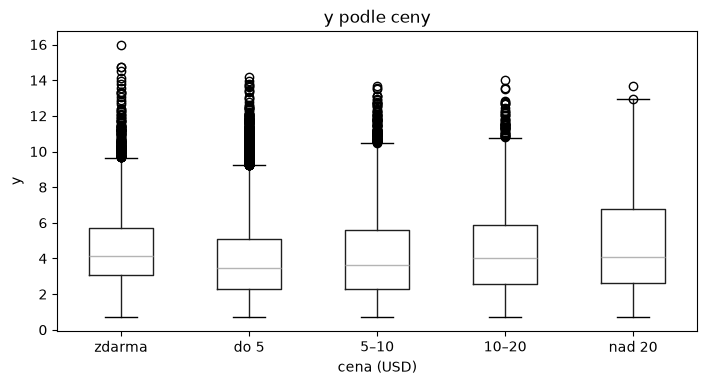

In [32]:
price_group = pd.cut(train["price"], [-1, 0, 5, 10, 20, 1000],
                     labels=["zdarma", "do 5", "5–10", "10–20", "nad 20"])
display(train.groupby(price_group, observed=True)["y"].agg(["count", "mean", "median"]).round(2))

train.assign(price_group=price_group).boxplot(column="y", by="price_group", grid=False, figsize=(8, 4))
plt.suptitle("")
plt.title("y podle ceny")
plt.xlabel("cena (USD)")
plt.ylabel("y")
plt.show()

#### Žánry

,count,mean
genres,,
Indie,33226,3.89
Action,19781,4.07
Casual,18639,3.61
Adventure,18045,4.17
Strategy,9028,4.20
Simulation,8885,4.31
RPG,7721,4.48
Early Access,3829,3.34
Free To Play,3317,5.17


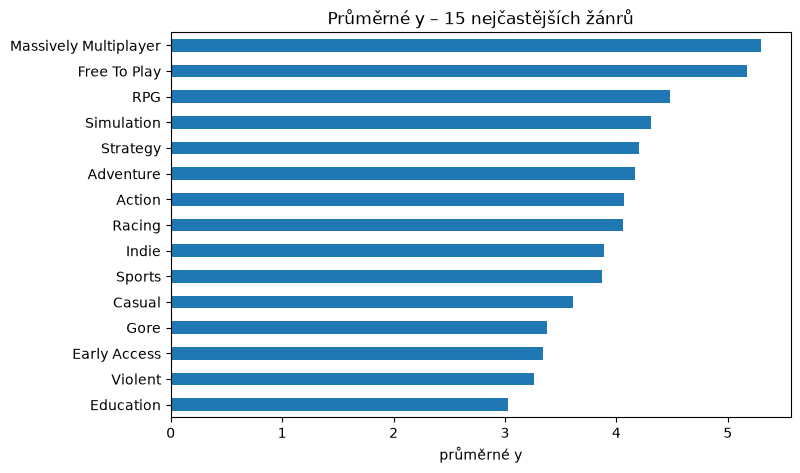

In [33]:
genres = train[["genres", "y"]].explode("genres")
genre_stats = genres.groupby("genres")["y"].agg(["count", "mean"]).sort_values("count", ascending=False).round(2)
display(genre_stats)

genre_stats.head(15)["mean"].sort_values().plot(kind="barh", figsize=(8, 5), title="Průměrné y – 15 nejčastějších žánrů")
plt.xlabel("průměrné y")
plt.ylabel("")
plt.show()

#### Kategorie

,count,mean
categories,,
Single-player,43306,4.03
Family Sharing,39600,3.96
Steam Achievements,23268,4.64
Steam Cloud,12356,5.14
Full controller support,10181,4.72
Multi-player,9386,4.84
Steam Trading Cards,9063,6.04
Partial Controller Support,6745,4.30
PvP,5816,4.53


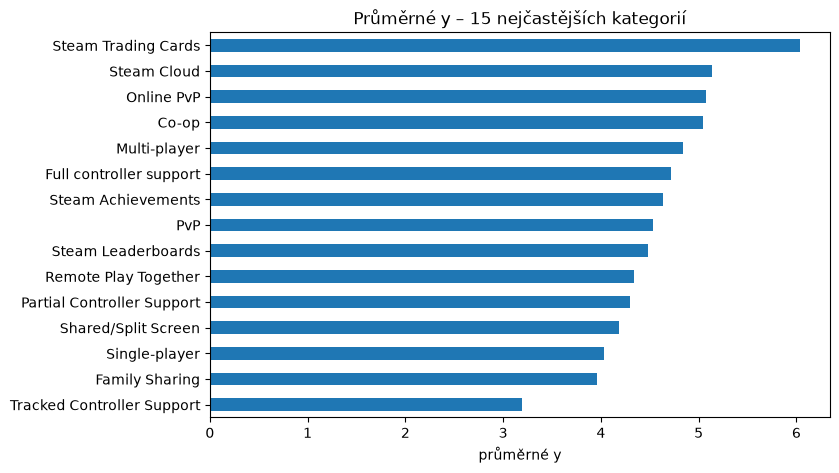

In [34]:
categories = train[["categories", "y"]].explode("categories")
category_stats = categories.groupby("categories")["y"].agg(["count", "mean"]).sort_values("count", ascending=False).round(2)
display(category_stats)

category_stats.head(15)["mean"].sort_values().plot(kind="barh", figsize=(8, 5), title="Průměrné y – 15 nejčastějších kategorií")
plt.xlabel("průměrné y")
plt.ylabel("")
plt.show()

#### Platformy

,windows,mac,linux
False,3.10,3.81,3.90
True,4.05,4.78,4.79


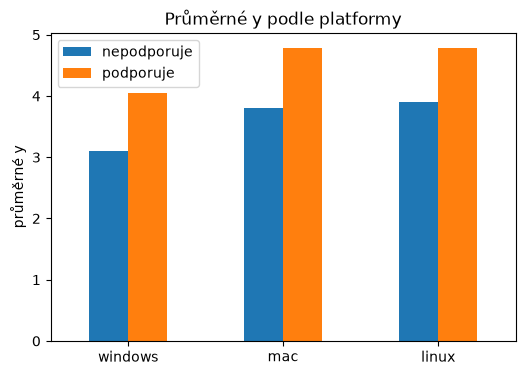

In [35]:
platforms = pd.DataFrame({p: train.groupby(p)["y"].mean() for p in ["windows", "mac", "linux"]}).round(2)
display(platforms)

platforms.T.plot(kind="bar", rot=0, figsize=(6, 4), title="Průměrné y podle platformy")
plt.ylabel("průměrné y")
plt.legend(["nepodporuje", "podporuje"])
plt.show()

#### Počet jazyků

,count,mean,median
supported_languages,,,
0,12,2.92,2.83
1,25268,3.41,3.14
2-3,7866,3.85,3.58
4-10,8472,5.31,5.15
nad 10,3947,5.82,5.47


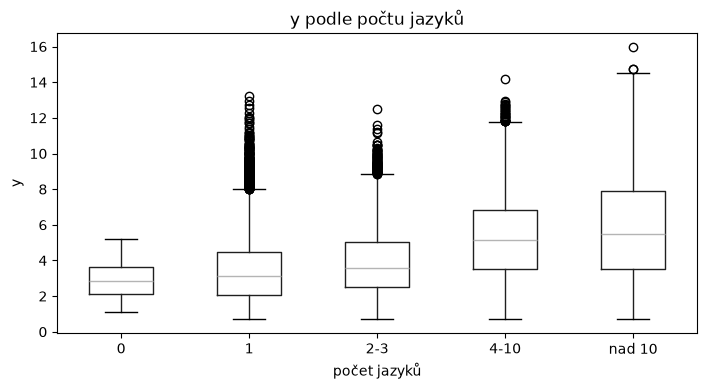

In [36]:
n_languages = train["supported_languages"].map(len)
language_group = pd.cut(n_languages, [-1, 0, 1, 3, 10, 200], labels=["0", "1", "2-3", "4-10", "nad 10"])
display(train.groupby(language_group, observed=True)["y"].agg(["count", "mean", "median"]).round(2))

train.assign(language_group=language_group).boxplot(column="y", by="language_group", grid=False, figsize=(8, 4))
plt.suptitle("")
plt.title("y podle počtu jazyků")
plt.xlabel("počet jazyků")
plt.ylabel("y")
plt.show()

#### Měsíc vydání

,count,mean
release,,
1,3001,3.99
2,3380,4.10
3,3622,4.10
4,3636,4.19
5,3789,4.17
6,3359,4.09
7,3896,3.93
8,4103,4.06
9,4133,4.04


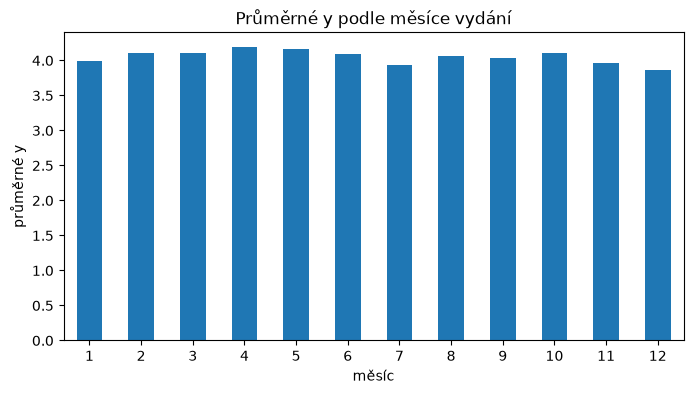

In [37]:
by_month = train.groupby(train["release"].dt.month)["y"].agg(["count", "mean"]).round(2)
display(by_month)

by_month["mean"].plot(kind="bar", rot=0, figsize=(8, 4), title="Průměrné y podle měsíce vydání")
plt.xlabel("měsíc")
plt.ylabel("průměrné y")
plt.show()

### Kódování a škálování
Implementováno ve funkcích `fit_features()` a `make_features()` v `prepare_data.py`.
Parametry kódování (slovníky žánrů a jazyků, průměr a směrodatná odchylka) se učí pouze z trénovací množiny
a stejně se aplikují na validační a testovací množinu.

1. **Rok vydání** – průměrné `y` s rokem výrazně klesá: standardizovaný vstup.
2. **Cena** – vztah k `y` není monotónní, hry zdarma se chovají jinak: standardizovaný `log(1 + cena)` a příznak `free`.
3. **Platformy** – podpora Macu a Linuxu souvisí s vyšším `y`: binární vstupy.
4. **Žánry** – multi-hot žánrů s aspoň 50 hrami v trénovací množině, bez `Early Access`, který odpovídá stavu v době stažení dat.
5. **Kategorie** – multi-hot pouze kategorií popisujících design hry; kategorie přidávané až po vydání (Trading Cards, Remote Play, přístupnost, Family Sharing…) by způsobily leakage.
6. **Jazyky** – `y` roste s počtem jazyků: standardizovaný `log(1 + počet jazyků)` a multi-hot jazyků, které má aspoň 1 % her v trénovací množině.
7. **Měsíc vydání** – vynechán, průměrné `y` se mezi měsíci téměř neliší.

#### Vstupy modelu

In [38]:
from prepare_data import fit_features, make_features

params = fit_features(train)
X_train = make_features(train, params)
X_val = make_features(val, params)
X_test = make_features(test, params)

print("Počet vstupů:", X_train.shape[1])
print("Kódované žánry:", params["genres"])
print("Kódované jazyky:", len(params["languages"]))

Počet vstupů: 77
Kódované žánry: ['Indie', 'Action', 'Casual', 'Adventure', 'Strategy', 'Simulation', 'RPG', 'Free To Play', 'Sports', 'Racing', 'Massively Multiplayer', 'Violent', 'Education', 'Gore', 'Utilities', 'Design & Illustration', 'Animation & Modeling', 'Nudity', 'Sexual Content', 'Software Training', 'Game Development', 'Video Production']
Kódované jazyky: 29


#### Kontrola škálování
Spojité vstupy mají na trénovací množině průměr 0 a směrodatnou odchylku 1; na validační a testovací množině se mohou lišit.

In [39]:
cols = ["log_price", "year", "log_languages"]
pd.DataFrame({
    "train": X_train[cols].mean(),
    "val": X_val[cols].mean(),
    "test": X_test[cols].mean(),
}).round(2)

,train,val,test
log_price,-0.0,0.21,0.25
year,-0.0,1.51,1.90
log_languages,-0.0,0.08,0.12
